# When correct mathematics meets floating-point arithmetic
### CS771 Mini-Project 2, Problem 1
### Group members

| Name | Roll no. |
|:-----|:---------|
| Allala Srisharan Reddy | 250102 |
| Ponish Bhatia  | 250781 |
| Rohan Rajeev Bharadwaj | 250911 |
| Saanvi Singh | 250934 |
| Sanath Koundinya | 250973 |

**Setup** — imports, seeds, PyTorch version, and CPU/GPU used.

In [1]:
import sys, platform, random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from decimal import Decimal, getcontext
from IPython.display import display

# ---- seeds (fixed for reproducibility) ----
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---- environment record ----
print("PyTorch   :", torch.__version__)
print("Device used for all computations in this notebook: CPU")   # tensors are created without .to(device)

PyTorch   : 2.9.1+cpu
Device used for all computations in this notebook: CPU


In [2]:
torch.cuda.is_available()

False

---
## Part I — A calculation that should work

Consider $F(a,b)=\log(e^a+e^b)$.

**I.1 Predict first.** Is $F(1000, 999)$ a finite real number? Approximately how large do you expect it to be?
In a naïve computer evaluation, what might go wrong?

> **Prediction:**
>
>
> **Is $F(1000, 999)$ finite?** Yes. Let $x=e^{a}$ and $y=e^{b}$ with $a=1000$, $b=999$.
>
> *Upper bound.* $x+y<xy$ holds whenever $(x-1)(y-1)>1$, which is true here because $x,y>2$. Hence
> $$e^{a}+e^{b}<e^{a}e^{b}=e^{a+b}\ \Rightarrow\ F(a,b)<\log e^{a+b}=a+b=1999.$$
>
> *Lower bound.* $e^{a}+e^{b}>\max(e^{a},e^{b})=e^{a}$, so
> $$F(a,b)>\log e^{a}=a=1000.$$
>
> Therefore $1000<F(1000,999)<1999$, which is a finite real number.
>
> **What might go wrong in a naïve computer evaluation?**
> - **Overflow.** $e^{1000}$ is far above the largest representable float, so `torch.exp` should return `inf`. The limits are $\approx 3.4\times10^{38}$ for float32 (overflow at input $\gtrsim 88.7$) and $\approx 1.8\times10^{308}$ for float64 (overflow at input $\gtrsim 709.8$). Since $1000$ exceeds both thresholds, **both** dtypes should fail: $e^{a}$ and $e^{b}$ both become `inf`, so $\infty+\infty=\infty$ and $\log(\infty)=\infty$.
> - The true answer is a perfectly ordinary number ($\approx 1000.31$), but the intermediate quantities $e^{a}, e^{b}$ are not representable, so the result is wrong ($\infty$).

**I.2 Naïve evaluation** in `float32` and then `float64`.

In [3]:
import torch
for dtype in (torch.float32, torch.float64):
    a = torch.tensor(1000., dtype=dtype)
    b = torch.tensor(999., dtype=dtype)
    print(dtype, torch.log(torch.exp(a) + torch.exp(b)))

torch.float32 tensor(inf)
torch.float64 tensor(inf, dtype=torch.float64)


**I.3 Repair with algebra, not a library function.** Let $c=\max(a,b)$, factor $e^c$ out of $e^a+e^b$, and derive an expression for $F(a,b)$
that only exponentiates $a-c$ and $b-c$.

*Derivation:* Let $c=\max(a,b)$. Factor $e^{c}$ out of the sum:
$$e^{a}+e^{b}=e^{c}\left(e^{a-c}+e^{b-c}\right).$$
Taking the logarithm and using $\log(uv)=\log u+\log v$ and $\log e^{c}=c$:
$$F(a,b)=\log\!\left(e^{a}+e^{b}\right)=c+\log\!\left(e^{a-c}+e^{b-c}\right),\qquad c=\max(a,b).$$

*Implement `stable_F(a, b)` and compare it with the naïve calculation on ordinary and extreme inputs.*

In [4]:
def stable_F(a, b):
    c = torch.maximum(a, b)
    return c + torch.log(torch.exp(a - c) + torch.exp(b - c))

In [5]:
import pandas as pd
from IPython.display import display

def naive_F(a, b):
    return torch.log(torch.exp(a) + torch.exp(b))

pairs = [(1., 2.), (0., 0.), (5., -3.), (50., 49.), (100., 99.),
         (1000., 999.), (1000., -1000.), (-1000., -1000.)]

for dtype in (torch.float32, torch.float64):
    rows = []
    for a, b in pairs:
        a_t, b_t = torch.tensor(a, dtype=dtype), torch.tensor(b, dtype=dtype)
        n, s = naive_F(a_t, b_t), stable_F(a_t, b_t)
        rows.append({
            "a": f"{a:g}",
            "b": f"{b:g}",
            "naive": f"{n.item():.6f}",
            "stable": f"{s.item():.6f}",
            "naive finite?": "yes" if torch.isfinite(n).item() else "NO",
        })
    df = pd.DataFrame(rows)
    display(df.style.set_caption(f"F(a, b) = log(e^a + e^b), {dtype}")
                    .hide(axis="index")
                    .set_properties(**{"text-align": "right"}))

a,b,naive,stable,naive finite?
1,2,2.313262,2.313262,yes
0,0,0.693147,0.693147,yes
5,-3,5.000335,5.000335,yes
50,49,50.313263,50.313263,yes
100,99,inf,100.313263,NO
1000,999,inf,1000.313232,NO
1000,-1000,inf,1000.000000,NO
-1000,-1000,-inf,-999.306824,NO


a,b,naive,stable,naive finite?
1,2,2.313262,2.313262,yes
0,0,0.693147,0.693147,yes
5,-3,5.000335,5.000335,yes
50,49,50.313262,50.313262,yes
100,99,100.313262,100.313262,yes
1000,999,inf,1000.313262,NO
1000,-1000,inf,1000.000000,NO
-1000,-1000,-inf,-999.306853,NO


**I.4 Generalise and justify.** Extend the derivation to $\log\big(\sum_{i=1}^{n}e^{x_i}\big)$. Explain
(a) why the transformed expression is *exactly* equal to the original in real arithmetic, and
(b) why none of the exponentials can overflow when $c=\max_i x_i$.

For $\mathbf x=(x_1,\dots,x_n)$ let $c=\max_i x_i$. Then
$$\log\Big(\sum_{i=1}^{n}e^{x_i}\Big)=c+\log\Big(\sum_{i=1}^{n}e^{x_i-c}\Big).$$

**(a) Exact equality in real arithmetic.** For every $i$, $e^{x_i}=e^{c}\,e^{x_i-c}$. Summing over $i$ and factoring the common constant $e^{c}$ out of the sum:
$$\sum_{i=1}^{n}e^{x_i}=e^{c}\sum_{i=1}^{n}e^{x_i-c}.$$
Both sides are positive, so taking $\log$ and using $\log(uv)=\log u+\log v$ and $\log e^{c}=c$ gives
$$\log\Big(\sum_i e^{x_i}\Big)=c+\log\Big(\sum_i e^{x_i-c}\Big).$$
No approximation was made, so the two expressions are equal in exact arithmetic.

**(b) No overflow when $c=\max_i x_i$.** Since $c\ge x_i$ for every $i$, each exponent satisfies $x_i-c\le 0$, so
$$0<e^{x_i-c}\le 1.$$
Every exponential is therefore at most $1$ and cannot overflow.

In [6]:
def stable_lse(x):
    c = torch.max(x)
    return c + torch.log(torch.sum(torch.exp(x - c)))

In [7]:
import pandas as pd
from IPython.display import display

def naive_lse(x):
    return torch.log(torch.sum(torch.exp(x)))

tests = {
    "[1, 2, 3]":              [1., 2., 3.],
    "[0]*5":                  [0.] * 5,
    "[10, -5, 3, 0, 7]":      [10., -5., 3., 0., 7.],
    "[100, 99, 98, 97]":      [100., 99., 98., 97.],
    "[1000]*5":               [1000.] * 5,
    "[1000, 999, 0, -1000]":  [1000., 999., 0., -1000.],
    "[-1000]*4":              [-1000.] * 4,
    "[-1000, -1001, -1002]":  [-1000., -1001., -1002.],
}

for dtype in (torch.float32, torch.float64):
    rows = []
    for name, v in tests.items():
        x = torch.tensor(v, dtype=dtype)
        n, s = naive_lse(x), stable_lse(x)
        rows.append({"x": name, "naive": f"{n.item():.6f}", "stable": f"{s.item():.6f}",
                     "naive finite?": "yes" if torch.isfinite(n).item() else "NO"})
    display(pd.DataFrame(rows).style.set_caption(f"log-sum-exp, {dtype}").hide(axis="index"))

# Sanity checks against known closed forms
x = torch.full((5,), 1000., dtype=torch.float64)
print(stable_lse(x).item(), 1000 + torch.log(torch.tensor(5., dtype=torch.float64)).item())   # lse of n equal values = x + log n

x = torch.tensor([3., -2., 0.5, 7.], dtype=torch.float64)
print(stable_lse(x + 500.).item() - 500., stable_lse(x).item())                               # shift invariance
print(stable_lse(torch.tensor([1000., 999.], dtype=torch.float64)).item(),
      stable_F(torch.tensor(1000., dtype=torch.float64), torch.tensor(999., dtype=torch.float64)).item())  # n = 2 matches Part I.3

x,naive,stable,naive finite?
"[1, 2, 3]",3.407606,3.407606,yes
[0]*5,1.609438,1.609438,yes
"[10, -5, 3, 0, 7]",10.049500,10.049500,yes
"[100, 99, 98, 97]",inf,100.440193,NO
[1000]*5,inf,1001.609436,NO
"[1000, 999, 0, -1000]",inf,1000.313232,NO
[-1000]*4,-inf,-998.613708,NO
"[-1000, -1001, -1002]",-inf,-999.592407,NO


x,naive,stable,naive finite?
"[1, 2, 3]",3.407606,3.407606,yes
[0]*5,1.609438,1.609438,yes
"[10, -5, 3, 0, 7]",10.049499,10.049499,yes
"[100, 99, 98, 97]",100.440190,100.440190,yes
[1000]*5,inf,1001.609438,NO
"[1000, 999, 0, -1000]",inf,1000.313262,NO
[-1000]*4,-inf,-998.613706,NO
"[-1000, -1001, -1002]",-inf,-999.592394,NO


1001.6094379124341 1001.6094379124341
7.019746241280814 7.0197462412808305
1000.3132616875182 1000.3132616875182


---
## Part II — From a trick to a library primitive

Check `torch.logaddexp(a, b)` and `torch.logsumexp(x, dim=...)` on the same ordinary and extreme inputs, and compare them with your implementation from Part I.

In [8]:
import pandas as pd
from IPython.display import display

pairs = [(1., 2.), (0., 0.), (5., -3.), (50., 49.), (100., 99.),
         (1000., 999.), (1000., -1000.), (-1000., -1000.)]

lse_tests = {
    "[1, 2, 3]":              [1., 2., 3.],
    "[0]*5":                  [0.] * 5,
    "[10, -5, 3, 0, 7]":      [10., -5., 3., 0., 7.],
    "[100, 99, 98, 97]":      [100., 99., 98., 97.],
    "[1000]*5":               [1000.] * 5,
    "[1000, 999, 0, -1000]":  [1000., 999., 0., -1000.],
    "[-1000]*4":              [-1000.] * 4,
    "[-1000, -1001, -1002]":  [-1000., -1001., -1002.],
}

def fmt(t):
    return f"{t.item():.6f}"

for dtype in (torch.float32, torch.float64):
    # ---- two-term: naive vs mine (Part I) vs torch.logaddexp ----
    rows = []
    for a, b in pairs:
        a_t, b_t = torch.tensor(a, dtype=dtype), torch.tensor(b, dtype=dtype)
        n, m, l = naive_F(a_t, b_t), stable_F(a_t, b_t), torch.logaddexp(a_t, b_t)
        rows.append({"a": f"{a:g}", "b": f"{b:g}", "naive": fmt(n), "mine": fmt(m),
                     "torch.logaddexp": fmt(l), "|mine - lib|": f"{abs((m - l).item()):.1e}"})
    display(pd.DataFrame(rows).style.set_caption(f"two terms, {dtype}").hide(axis="index"))

    # ---- n-term: naive vs mine vs torch.logsumexp ----
    rows = []
    for name, v in lse_tests.items():
        x = torch.tensor(v, dtype=dtype)
        n, m, l = naive_lse(x), stable_lse(x), torch.logsumexp(x, dim=0)
        rows.append({"x": name, "naive": fmt(n), "mine": fmt(m),
                     "torch.logsumexp": fmt(l), "|mine - lib|": f"{abs((m - l).item()):.1e}"})
    display(pd.DataFrame(rows).style.set_caption(f"n terms, {dtype}").hide(axis="index"))

a,b,naive,mine,torch.logaddexp,|mine - lib|
1,2,2.313262,2.313262,2.313262,0.0e+00
0,0,0.693147,0.693147,0.693147,0.0e+00
5,-3,5.000335,5.000335,5.000335,0.0e+00
50,49,50.313263,50.313263,50.313263,0.0e+00
100,99,inf,100.313263,100.313263,0.0e+00
1000,999,inf,1000.313232,1000.313232,0.0e+00
1000,-1000,inf,1000.000000,1000.000000,0.0e+00
-1000,-1000,-inf,-999.306824,-999.306824,0.0e+00


x,naive,mine,torch.logsumexp,|mine - lib|
"[1, 2, 3]",3.407606,3.407606,3.407606,0.0e+00
[0]*5,1.609438,1.609438,1.609438,0.0e+00
"[10, -5, 3, 0, 7]",10.049500,10.049500,10.049500,0.0e+00
"[100, 99, 98, 97]",inf,100.440193,100.440193,0.0e+00
[1000]*5,inf,1001.609436,1001.609436,0.0e+00
"[1000, 999, 0, -1000]",inf,1000.313232,1000.313232,0.0e+00
[-1000]*4,-inf,-998.613708,-998.613708,0.0e+00
"[-1000, -1001, -1002]",-inf,-999.592407,-999.592407,0.0e+00


a,b,naive,mine,torch.logaddexp,|mine - lib|
1,2,2.313262,2.313262,2.313262,0.0e+00
0,0,0.693147,0.693147,0.693147,0.0e+00
5,-3,5.000335,5.000335,5.000335,0.0e+00
50,49,50.313262,50.313262,50.313262,0.0e+00
100,99,100.313262,100.313262,100.313262,0.0e+00
1000,999,inf,1000.313262,1000.313262,0.0e+00
1000,-1000,inf,1000.000000,1000.000000,0.0e+00
-1000,-1000,-inf,-999.306853,-999.306853,0.0e+00


x,naive,mine,torch.logsumexp,|mine - lib|
"[1, 2, 3]",3.407606,3.407606,3.407606,0.0e+00
[0]*5,1.609438,1.609438,1.609438,0.0e+00
"[10, -5, 3, 0, 7]",10.049499,10.049499,10.049499,0.0e+00
"[100, 99, 98, 97]",100.440190,100.440190,100.440190,0.0e+00
[1000]*5,inf,1001.609438,1001.609438,0.0e+00
"[1000, 999, 0, -1000]",inf,1000.313262,1000.313262,0.0e+00
[-1000]*4,-inf,-998.613706,-998.613706,0.0e+00
"[-1000, -1001, -1002]",-inf,-999.592394,-999.592394,0.0e+00


**Explain (do not just record that they "work"):**
1. Why do these functions exist, and which failure mode of the naïve expression do they avoid?
2. Why are they numerical implementations of familiar mathematics rather than new operations?

**Very negative inputs.** Try inputs such as $(-1000, -1001)$ and comment.

In [9]:
import pandas as pd
from IPython.display import display

neg_pairs = [(-50., -51.), (-90., -91.), (-100., -101.), (-104., -105.), (-200., -200.),
             (-700., -701.), (-740., -741.), (-746., -747.), (-1000., -1001.), (-1000., -1000.)]

def ref_F(a, b):   # float64 reference a + log(1 + e^(b-a)), valid here because b <= a
    d = torch.tensor(b - a, dtype=torch.float64)
    return a + torch.log1p(torch.exp(d)).item()

for dtype in (torch.float32, torch.float64):
    rows = []
    for a, b in neg_pairs:
        a_t, b_t = torch.tensor(a, dtype=dtype), torch.tensor(b, dtype=dtype)
        n, m, l = naive_F(a_t, b_t), stable_F(a_t, b_t), torch.logaddexp(a_t, b_t)
        r = ref_F(a, b)
        rows.append({"a": f"{a:g}", "b": f"{b:g}", "exp(a)": f"{torch.exp(a_t).item():.1e}",
                     "naive": f"{n.item():.6f}", "mine": f"{m.item():.6f}",
                     "torch.logaddexp": f"{l.item():.6f}", "err naive": f"{abs(n.item() - r):.1e}",
                     "err mine": f"{abs(m.item() - r):.1e}"})
    display(pd.DataFrame(rows).style.set_caption(f"very negative inputs, {dtype}").hide(axis="index"))

# Edge case: every input is -inf (true answer: log 0 = -inf)
x = torch.full((2,), -float("inf"))
print("naive:", naive_lse(x).item(), " mine:", stable_lse(x).item(), " torch.logsumexp:", torch.logsumexp(x, dim=0).item())

a,b,exp(a),naive,mine,torch.logaddexp,err naive,err mine
-50,-51,1.9e-22,-49.686737,-49.686737,-49.686737,1.3e-06,1.3e-06
-90,-91,8.2e-40,-89.686737,-89.686737,-89.686737,1.3e-06,1.3e-06
-100,-101,3.8e-44,-99.668015,-99.686737,-99.686737,1.9e-02,1.3e-06
-104,-105,0.0e+00,-inf,-103.686737,-103.686737,inf,1.3e-06
-200,-200,0.0e+00,-inf,-199.306854,-199.306854,inf,1.4e-06
-700,-701,0.0e+00,-inf,-699.686768,-699.686768,inf,2.9e-05
-740,-741,0.0e+00,-inf,-739.686768,-739.686768,inf,2.9e-05
-746,-747,0.0e+00,-inf,-745.686768,-745.686768,inf,2.9e-05
-1000,-1001,0.0e+00,-inf,-999.686768,-999.686768,inf,2.9e-05
-1000,-1000,0.0e+00,-inf,-999.306824,-999.306824,inf,2.9e-05


a,b,exp(a),naive,mine,torch.logaddexp,err naive,err mine
-50,-51,1.9e-22,-49.686738,-49.686738,-49.686738,0.0e+00,0.0e+00
-90,-91,8.2e-40,-89.686738,-89.686738,-89.686738,0.0e+00,0.0e+00
-100,-101,3.7e-44,-99.686738,-99.686738,-99.686738,0.0e+00,0.0e+00
-104,-105,6.8e-46,-103.686738,-103.686738,-103.686738,0.0e+00,0.0e+00
-200,-200,1.4e-87,-199.306853,-199.306853,-199.306853,0.0e+00,0.0e+00
-700,-701,9.9e-305,-699.686738,-699.686738,-699.686738,0.0e+00,0.0e+00
-740,-741,4.2e-322,-739.686482,-739.686738,-739.686738,2.6e-04,0.0e+00
-746,-747,0.0e+00,-inf,-745.686738,-745.686738,inf,0.0e+00
-1000,-1001,0.0e+00,-inf,-999.686738,-999.686738,inf,0.0e+00
-1000,-1000,0.0e+00,-inf,-999.306853,-999.306853,inf,0.0e+00


naive: -inf  mine: nan  torch.logsumexp: -inf


**Why do `logaddexp` and `logsumexp` exist?**
The quantity $\log\sum_i e^{x_i}$ appears constantly in ML: the softmax denominator, cross-entropy, log-likelihoods of mixture models. The naïve expression fails *silently*, returning `inf` or `-inf` and no error, so a good library provides one tested version instead of every user re-deriving the trick. The library version also covers vectorisation (`dim`).

**Which failure mode do they avoid?**
The naïve formula fails because of the *intermediate* values $e^{x_i}$. For large positive $x_i$ these overflow to `inf` (above about $88.7$ in float32 and $709.8$ in float64), and for very negative $x_i$ they underflow to $0$, so the sum is $0$ and $\log 0=-\infty$. In both cases the true result is an ordinary finite number. The primitives subtract $c=\max_i x_i$ first, so every exponent is $\le 0$, every $e^{x_i-c}\in(0,1]$, and the sum lies in $[1,n]$. Nothing overflows, and the $\log$ never sees $0$.

**Why are they numerical implementations of familiar mathematics, not new operations?**
They compute exactly the same function as $\log\sum_i e^{x_i}$. The only change is the order of operations, justified by two identities: $e^{x_i}=e^{c}e^{x_i-c}$ (factor out a constant) and $\log(uv)=\log u+\log v$. In real arithmetic the shifted and unshifted forms are identical, and `logaddexp` is just the case $n=2$. So the library changes how the formula is evaluated, not what it means.

**Very negative inputs.** The naïve formula fails here too, but in a different way from the large-positive case: **underflow**, not overflow.

- *Total underflow.* In float32, $e^{x}$ becomes exactly $0$ below about $x\approx-103.3$; in float64 below about $-744.4$. Both terms are then $0$, so $\log(0+0)=-\infty$ although the true value is a finite number such as $F(-1000,-1001)\approx-999.687$. Examples: float32 $(-104,-105)$ and float64 $(-746,-747)$.
- *Silent loss of accuracy before that.* Just above the threshold the results are denormal numbers with very few significant digits, so the naïve answer is finite but wrong. For float32 $(-100,-101)$ the naïve result is $-99.668$ against a true value of $-99.687$, an error of about $2\times10^{-2}$. For float64 $(-740,-741)$ the error is about $3\times10^{-4}$.
- *The shifted form is unaffected.* After subtracting $c=\max(a,b)$ the largest term is $e^{0}=1$, so the sum is always in $[1,n]$ and the result is correct to rounding error, even for inputs like $-1000$. `torch.logaddexp` agrees. In other words, the max-shift cures underflow as well as overflow, because it moves the *largest* term to $1$ whatever its original size.
- *The stable form's error comes from the dtype, not from the method.* float32 has about 7 significant digits, so a result near $-1000$ is only accurate to about $10^{-4}$, whereas float64 is accurate to about $10^{-13}$.
- *A remaining edge case.* If every input is $-\infty$ the true value is $\log 0=-\infty$. My `stable_lse` computes $c=-\infty$ and then $-\infty-(-\infty)=\text{nan}$, so it returns `nan`, while the library function is expected to return `-inf`. The library handles infinite maxima as a special case. My version assumes at least one finite input.

**Bridge to ML.** For logits $\mathbf z=(z_0,\dots,z_{K-1})$ and correct class $y$:
$$p_j=\frac{e^{z_j}}{\sum_i e^{z_i}},\qquad L(\mathbf z,y)=-\log p_y=\log\Big(\sum_i e^{z_i}\Big)-z_y.$$

Explain how Part I is connected to computing softmax cross-entropy. Does a stable log-sum-exp automatically guarantee that all related computations are stable?
(Keep this as an open question; revisit it in the Reflection.)

**Connection to Part I.** The loss is $L(\mathbf z,y)=\log\big(\sum_i e^{z_i}\big)-z_y$. The first term is exactly the log-sum-exp from Part I with $x_i=z_i$. Computing it naïvely (exponentiate every logit, sum, take the $\log$) would overflow for large positive logits, and the softmax probabilities $p_j=e^{z_j}/\sum_i e^{z_i}$ would become $\infty/\infty=\text{nan}$. With the max-shift, $L=\big(c+\log\sum_i e^{z_i-c}\big)-z_y$ with $c=\max_i z_i$, which is finite and accurate. This is why `F.cross_entropy` takes logits and not probabilities.

**Open question (my original guess: yes).** Does a stable log-sum-exp automatically make everything related stable? My original guess was **yes**. The reasoning was:
- The only failure I knew from Part I was overflow/underflow of $e^{z_i}$. The max-shift removes it, so $\mathrm{lse}(\mathbf z)$ is finite and accurate.
- Everything else in cross-entropy is built from that: the probabilities $p_j=\exp\big(z_j-\mathrm{lse}(\mathbf z)\big)$ have a non-positive exponent, so they lie in $[0,1]$ and cannot overflow.
- The gradient formula $g_j=p_j-\mathbf 1[j=y]$ looked harmless: it uses only these bounded probabilities and one subtraction of $1$. I did not see any new place where an exponential could blow up, so I expected a stable log-sum-exp to make the gradient stable too.
- I had not yet met the idea that subtracting two almost equal numbers can lose accuracy, so I did not consider the subtraction $p_y-1$ as a possible problem.

---
## Part III — A second, subtler failure

In exact arithmetic the cross-entropy gradient is
$$g_j:=\frac{\partial L}{\partial z_j}=p_j-\mathbf 1[j=y].\tag{1}$$

**III.1 Show that $\sum_j g_j=0$.**

From (1), $g_j=p_j-\mathbf 1[j=y]$. Summing over all classes $j=0,\dots,K-1$:
$$\sum_{j} g_j=\sum_{j}p_j-\sum_{j}\mathbf 1[j=y].$$
The probabilities form a softmax, so
$$\sum_j p_j=\frac{\sum_j e^{z_j}}{\sum_i e^{z_i}}=1 .$$
The indicator $\mathbf 1[j=y]$ equals $1$ for exactly one index ($j=y$) and $0$ for all others, so $\sum_j \mathbf 1[j=y]=1$. Therefore
$$\sum_j g_j=1-1=0.$$

**III.2 Predict first.** Take $K=5$, $y=0$ and logits $\mathbf z(m)=(m,0,0,0,0)$ for $m\ge 0$. As $m$ grows, what are the signs of $g_0$ and $g_1$?
Can either be exactly zero at a finite $m$ in real arithmetic?

> **Prediction (written before running the code):**
>
> Take $K=5$, $y=0$, $\mathbf z(m)=(m,0,0,0,0)$. The loss is
> $$L=\log\big(e^{m}+1+1+1+1\big)-z_y=\log\big(e^{m}+4\big)-m,$$
> and since $z_0=m$ and $\sum_i e^{z_i}=e^{m}+4$, the probabilities are $p_0=\dfrac{e^{m}}{e^{m}+4}$ and $p_1=\dfrac{1}{e^{m}+4}$.
>
> *Target gradient ($j=0$):*
> $$g_0=\frac{\partial L}{\partial z_0}=p_0-\mathbf 1[0=0]=\frac{e^{z_0}}{\sum_i e^{z_i}}-1=\frac{e^{m}}{e^{m}+4}-1=\frac{-4}{e^{m}+4}.$$
>
> *Non-target gradient ($j=1$):*
> $$g_1=\frac{\partial L}{\partial z_1}=p_1-\mathbf 1[1=0]=\frac{e^{z_1}}{\sum_i e^{z_i}}=\frac{1}{e^{m}+4}.$$
>
> **Signs:** $g_0<0$ and $g_1>0$ for every $m$.
>
> **Can either be exactly zero at a finite $m$ in real arithmetic? No.** For finite $m$, $e^{m}+4$ is finite and positive, so $g_1=\dfrac{1}{e^{m}+4}>0$ and $g_0=-\dfrac{4}{e^{m}+4}<0$ strictly. Both tend to $0$ as $m\to\infty$, but they never reach $0$.

**III.3 Library gradient** (starting point from the problem sheet).

In [10]:
import torch
import torch.nn.functional as F

def library_gradient(m, dtype=torch.float32):
    z = torch.tensor([[m, 0., 0., 0., 0.]], dtype=dtype, requires_grad=True)
    loss = F.cross_entropy(z, torch.tensor([0]))
    loss.backward()
    return z.grad.detach()[0]

for m in (5., 10., 15., 20., 30., 40.):
    g = library_gradient(m)
    print(m, g[0].item(), g[1].item(), g.sum().item())

5.0 -0.02624446153640747 0.006561112590134144 -1.210719347000122e-08
10.0 -0.00018161535263061523 4.539170186035335e-05 -4.854518920183182e-08
15.0 -1.430511474609375e-06 3.0590203436986485e-07 -2.069032518647873e-07
20.0 0.0 2.06115369216775e-09 8.244614768671e-09
30.0 0.0 9.357622912219837e-14 3.743049164887935e-13
40.0 0.0 4.24835413113866e-18 1.699341652455464e-17


**III.4 Denser grid of $m$ in `float32` and `float64`.** Find a margin (if one occurs) at which $g_0$ is computed as exactly zero while a non-target gradient is not. Use $\left|\sum_j g_j\right|$ as a diagnostic.

In [11]:
import numpy as np
import pandas as pd
from IPython.display import display

ms = np.arange(0., 800.25, 0.25)          

def scan(dtype):
    rows = []
    for m in ms:
        g = library_gradient(float(m), dtype)
        rows.append({"m": m, "g0": g[0].item(), "g1": g[1].item(), "sum": g.sum().item()})
    return pd.DataFrame(rows)

scans = {dt: scan(dt) for dt in (torch.float32, torch.float64)}

for dt, df in scans.items():
    hit  = df[(df.g0 == 0) & (df.g1 != 0)]      # g0 collapsed, a non-target gradient survives
    dead = df[(df.g0 == 0) & (df.g1 == 0)]      # everything underflowed
    print(dt, "| first m with g0 == 0 but g1 != 0:", hit.m.iloc[0] if len(hit) else None,
          "| first m with all gradients == 0:", dead.m.iloc[0] if len(dead) else None)

    show = df[df.m.isin([5, 10, 15, 16, 17, 18, 20, 30, 36, 38, 40, 50, 100, 104, 745, 746])].copy()
    show["exact g0"] = -4 * np.exp(-show.m) / (1 + 4 * np.exp(-show.m))
    show["|sum|"] = show["sum"].abs()
    show = show.drop(columns="sum")
    display(show.style.format({"m": "{:g}", "g0": "{:.3e}", "g1": "{:.3e}",
                               "exact g0": "{:.3e}", "|sum|": "{:.1e}"})
                      .hide(axis="index").set_caption(f"library gradient, {dt}"))

torch.float32 | first m with g0 == 0 but g1 != 0: 16.75 | first m with all gradients == 0: 104.0


m,g0,g1,exact g0,|sum|
5,-2.624e-02,6.561e-03,-2.624e-02,1.2e-08
10,-1.816e-04,4.539e-05,-1.816e-04,4.9e-08
15,-1.431e-06,3.059e-07,-1.224e-06,2.1e-07
16,-4.768e-07,1.125e-07,-4.501e-07,2.7e-08
17,0.000e+00,4.140e-08,-1.656e-07,1.7e-07
18,0.000e+00,1.523e-08,-6.092e-08,6.1e-08
20,0.000e+00,2.061e-09,-8.245e-09,8.2e-09
30,0.000e+00,9.358e-14,-3.743e-13,3.7e-13
36,0.000e+00,2.320e-16,-9.278e-16,9.3e-16
38,0.000e+00,3.139e-17,-1.256e-16,1.3e-16


torch.float64 | first m with g0 == 0 but g1 != 0: 36.75 | first m with all gradients == 0: 745.25


m,g0,g1,exact g0,|sum|
5,-2.624e-02,6.561e-03,-2.624e-02,4.4e-16
10,-1.816e-04,4.539e-05,-1.816e-04,7.5e-18
15,-1.224e-06,3.059e-07,-1.224e-06,3.1e-16
16,-4.501e-07,1.125e-07,-4.501e-07,7.1e-17
17,-1.656e-07,4.140e-08,-1.656e-07,2.9e-16
18,-6.092e-08,1.523e-08,-6.092e-08,4.4e-17
20,-8.245e-09,2.061e-09,-8.245e-09,2.4e-16
30,-3.739e-13,9.358e-14,-3.743e-13,3.8e-16
36,-8.882e-16,2.320e-16,-9.278e-16,4.0e-17
38,0.000e+00,3.139e-17,-1.256e-16,1.3e-16


**Collapse margin.** On the grid $m\in[0,800]$ (step $0.25$) the library gradient behaves as follows:
- **float32:** $g_0$ is exactly `0.0` from about $m\approx 17$ onward, while $g_1\approx 4\times10^{-8}$ and keeps shrinking smoothly. The diagnostic $\left|\sum_j g_j\right|$ jumps from about $10^{-7}$ (rounding noise) to $4e^{-m}$, which is the full size of the missing $g_0$. All gradients underflow to $0$ only at $m\approx 104$.
- **float64:** the same collapse happens, but later, at about $m\approx 37$, and all gradients vanish only near $m\approx 745$.
- Before the collapse $g_0$ is not exact either: in float32 at $m=15$ it is $-1.431\times10^{-6}$ against the true $-1.224\times10^{-6}$ (about $17\%$ off).
- In real arithmetic $g_0=-4/(e^m+4)<0$ for every $m$ (Part III.2), so $g_0=0$ is an artefact.

**III.5** Explain why computing $p_y-1$ is vulnerable when $p_y$ is very close to 1, and why the max-subtraction trick of Part I does not necessarily fix it.

**Why $p_y-1$ is vulnerable, and why the max-shift does not fix it.** When $p_y$ is very close to $1$, the exact value $g_y=p_y-1=-4e^{-m}/(1+4e^{-m})$ is tiny. But $p_y=1/S$ with $S=\sum_i e^{z_i-c}=1+4e^{-m}$ must first be computed as a floating-point number near $1$, where neighbouring values are spaced by $\varepsilon\approx1.2\times10^{-7}$ (float32) or $2.2\times10^{-16}$ (float64). The denominator is accumulated one term at a time, so each non-target term $e^{-m}$ is added separately to a number near $1$. If $e^{-m}<\varepsilon/2$, every such addition is rounded away, so $S=1$ exactly, $p_y=1$, and the subtraction $p_y-1$ returns $0$. This happens for $m>\ln(2/\varepsilon)$, i.e. $m>16.64$ in float32 and $m>36.74$ in float64, which matches the first exact zeros found in the grid ($16.75$ and $36.75$); the check cell below confirms it. Just below that threshold each term is instead rounded *up* to a whole $\varepsilon$, so $S$ is overestimated (at $m=16.5$ in float32 the computed $S$ is $1+4\varepsilon$ instead of $1+2.29\varepsilon$), which is why the library is already about $75\%$ off before it reaches $0$. (Exact thresholds can vary slightly with hardware and software version.)

The *absolute* error is tiny (below $10^{-7}$ or $10^{-16}$), but the *relative* error is $100\%$, since the correct answer was never $0$. The max-shift of Part I does not help because it solves a different problem: it keeps the exponentials $e^{z_i-c}$ from overflowing. The trouble is not the size of any exponential but the final $p_y-1$, which subtracts $1$ from a number that was rounded to $1$. The non-target gradients $g_j=p_j$ are accurate because they involve no subtraction.

*Why do non-target gradients also reach $0$ (at $m\approx104$ in float32 and $m\approx745$ in float64)?* This is **underflow**, not cancellation. $g_1=1/(e^{m}+4)\approx e^{-m}$ is computed without any subtraction, but once $e^{-m}$ is smaller than half the smallest positive float ($2^{-150}$ in float32, $2^{-1075}$ in float64, i.e. $m>150\ln2$ and $m>1075\ln2$) it has no representable value and is rounded to $0$. The collapse of $g_0$ at $m\approx17$ (float32) and $m\approx37$ (float64) is different: its true value there is still comfortably representable, and the library returns $0$ only because of the rounding of $S$ and the subtraction $p_y-1$. A better algorithm can fix the second failure but not the first.

In [12]:
# Mechanism check: why does the library's g_y collapse exactly where it does?
def denominator(m, dtype):
    e = torch.exp(torch.tensor(-float(m), dtype=dtype))     # each non-target term e^{z_j - max}
    S = torch.tensor(1., dtype=dtype)                       # target term e^0 = 1
    for _ in range(4):                                      # add the 4 non-target terms one at a time
        S = S + e
    return S

for dt, grid in ((torch.float32, [15., 16., 16.5, 16.75, 17.]), (torch.float64, [35., 36., 36.5, 36.75, 37.])):
    eps = torch.finfo(dt).eps
    print(f"{dt}: eps = {eps:.3e}, predicted collapse threshold ln(2/eps) = {np.log(2/eps):.2f}")
    rows = []
    for m in grid:
        S = denominator(m, dt)
        rows.append({"m": m, "(S-1)/eps": f"{((S-1)/eps).item():.2f}", "true 4e^-m/eps": f"{4*np.exp(-m)/eps:.2f}",
                     "library g0": f"{library_gradient(m, dt)[0].item():.3e}", "exact g0": f"{-4*np.exp(-m)/(1+4*np.exp(-m)):.3e}"})
    display(pd.DataFrame(rows).style.hide(axis="index").set_caption(f"denominator S = 1 + 4e^-m, {dt}"))

torch.float32: eps = 1.192e-07, predicted collapse threshold ln(2/eps) = 16.64


m,(S-1)/eps,true 4e^-m/eps,library g0,exact g0
15.000000,12.00,10.26,-1.431e-06,-1.224e-06
16.000000,4.00,3.78,-4.768e-07,-4.501e-07
16.500000,4.00,2.29,-4.768e-07,-2.730e-07
16.750000,0.00,1.78,0.000e+00,-2.126e-07
17.000000,0.00,1.39,0.000e+00,-1.656e-07


torch.float64: eps = 2.220e-16, predicted collapse threshold ln(2/eps) = 36.74


m,(S-1)/eps,true 4e^-m/eps,library g0,exact g0
35.000000,12.00,11.36,-2.665e-15,-2.522e-15
36.000000,4.00,4.18,-8.882e-16,-9.278e-16
36.500000,4.00,2.53,-8.882e-16,-5.627e-16
36.750000,0.00,1.97,0.000e+00,-4.383e-16
37.000000,0.00,1.54,0.000e+00,-3.413e-16


---
## Part IV — Your challenge: design a better gradient

For a general number of classes $K$ and any correct label $y$, derive and implement a gradient that is mathematically identical to (1)
but avoids directly computing $p_y-1$.

**IV.1 Correct-class gradient.** Start from the exact expression for $g_y$. Rewrite it using the non-target logits and $z_y$, in a form that does not subtract two almost-equal numbers.

**IV.2 Non-target gradients** $g_j$, $j\neq y$. Think about overflow and underflow: the tools of Part II may help but are not by themselves a complete solution.

**Solution-**

**IV.1 Correct-class gradient.** Since $\sum_{j=0}^{K-1}p_j=1$,
$$g_y=p_y-1=p_y-\sum_{j=0}^{K-1}p_j=-\sum_{j\neq y}p_j .$$
Every $p_j\ge 0$, so $g_y$ is minus a sum of non-negative numbers. There is no subtraction of nearly equal numbers, hence no cancellation, and $g_y$ can be evaluated to full relative precision even when $p_y\approx1$.

**IV.2 Non-target gradients.** For $j\neq y$, $\mathbf 1[j=y]=0$, so
$$g_j=p_j-\mathbf 1[j=y]=p_j .$$
*Evaluating $p_j$ safely.* Writing $p_j=\dfrac{e^{z_j}}{\sum_i e^{z_i}}=\exp\big(z_j-\mathrm{lse}(\mathbf z)\big)$, where $\mathrm{lse}$ is computed with the max-shift of Part I, the exponent is $\le 0$ because $\mathrm{lse}(\mathbf z)\ge\max_i z_i\ge z_j$. So $p_j\in[0,1]$ and nothing overflows. The only remaining limit is underflow: a $p_j$ below the smallest representable float becomes $0$, but then its true value is not representable anyway.

**IV.3 Implementation.** `stable_grad(logits, y)` for a single length-$K$ tensor. Do **not** obtain it by autodifferentiating `F.cross_entropy`.

In [13]:
def stable_grad(logits, y):
    """Cross-entropy gradient for one length-K logit vector, without computing p_y - 1."""
    K = logits.shape[0]
    lse = stable_lse(logits)                       # max-shifted log-sum-exp (Part I)
    p = torch.exp(logits - lse)                    # all probabilities, each in [0, 1]
    mask = torch.ones(K, dtype=torch.bool, device=logits.device)
    mask[y] = False
    g = p.clone()                                  # g_j = p_j for j != y
    g[y] = -p[mask].sum()                          # g_y = -(sum of non-target p_j): no cancellation
    return g

*Tests: several $K$, labels and logit patterns.*

In [14]:
import pandas as pd
import torch.nn.functional as F
from decimal import Decimal, getcontext
from IPython.display import display

def exact_grad(logits, y):
    """Reference: the textbook formula p_j - 1[j=y], evaluated with enough decimal digits
    that p_y - 1 does not cancel. Independent of my rewrite."""
    z = [Decimal(v) for v in logits.double().tolist()]
    getcontext().prec = int(float(max(z) - min(z)) / 2.302585) + 120
    c = max(z)
    e = [(v - c).exp() for v in z]
    s = sum(e)
    return [ei / s - (1 if j == y else 0) for j, ei in enumerate(e)]

def lib_grad(logits, y):
    z = logits.clone().requires_grad_(True)
    F.cross_entropy(z[None], torch.tensor([y])).backward()
    return z.grad

def max_rel_err(g, ref, dtype):
    tiny = torch.finfo(dtype).tiny           # only judge components that are representable as normal floats
    worst = 0.0
    for gi, ri in zip(g.double().tolist(), ref):
        if abs(ri) >= tiny:
            worst = max(worst, float(abs(Decimal(gi) - ri) / abs(ri)))
    return worst

def rel_err_or_na(g, ref, dtype):    # relative error is undefined when every true value is below the smallest normal float
    if all(abs(r) < torch.finfo(dtype).tiny for r in ref):
        return "n/a (true gradient is 0 or below the smallest float)"
    return f"{max_rel_err(g, ref, dtype):.1e}"

torch.manual_seed(SEED)
cases = [
    ("K=2, y=1 | two classes, small logits, target is the smaller one",          torch.tensor([0.5, -0.5]), 1),
    ("K=5, y=0 | random logits, std 1",                            torch.randn(5), 0),
    ("K=10, y=7 | random logits, std 3 (non-zero target)",         3 * torch.randn(10), 7),
    ("K=100, y=42 | random logits, std 10 (many classes)",         10 * torch.randn(100), 42),
    ("K=1, y=0 | single class (p_y = 1 exactly)",                  torch.tensor([3.]), 0),
    ("K=5, y=0 | target margin 100, confident and correct",        torch.tensor([100., 0, 0, 0, 0]), 0),
    ("K=5, y=0 | target margin 700, below float32 range",          torch.tensor([700., 0, 0, 0, 0]), 0),
    ("K=5, y=2 | target margin 50, non-zero target index",         torch.tensor([0., 0, 50., 0, 0]), 2),
    ("K=3, y=1 | other logit 1000 higher, confidently wrong",      torch.tensor([1000., 0, 0]), 1),
    ("K=3, y=0 | extreme spread, logits +1e4 / -1e4 / 0",          torch.tensor([1e4, -1e4, 0]), 0),
]

for dtype in (torch.float32, torch.float64):
    rows = []
    for name, z, y in cases:
        z = z.to(dtype)
        ref, gm, gl = exact_grad(z, y), stable_grad(z, y), lib_grad(z, y)
        assert gm.shape == z.shape and torch.isfinite(gm).all()
        assert gm[y] <= 0 and (torch.cat([gm[:y], gm[y+1:]]) >= 0).all()      # correct signs
        rows.append({"case": name,
                     "rel err mine": rel_err_or_na(gm, ref, dtype),
                     "rel err library": rel_err_or_na(gl, ref, dtype),
                     "|sum| mine": f"{gm.sum().abs().item():.1e}",
                     "|sum| library": f"{gl.sum().abs().item():.1e}"})
    display(pd.DataFrame(rows).style.set_caption(f"gradient vs 1000-digit-class reference, {dtype}").hide(axis="index"))

case,rel err mine,rel err library,|sum| mine,|sum| library
"K=2, y=1 | two classes, small logits, target is the smaller one",2.6e-08,2.6e-08,0.0e+00,0.0e+00
"K=5, y=0 | random logits, std 1",2.5e-07,1.1e-07,4.5e-08,4.5e-08
"K=10, y=7 | random logits, std 3 (non-zero target)",3.3e-07,1.3e-07,6.0e-08,6.0e-08
"K=100, y=42 | random logits, std 10 (many classes)",3.0e-06,3.0e-06,2.8e-09,1.2e-07
"K=1, y=0 | single class (p_y = 1 exactly)",n/a (true gradient is 0 or below the smallest float),n/a (true gradient is 0 or below the smallest float),0.0e+00,0.0e+00
"K=5, y=0 | target margin 100, confident and correct",n/a (true gradient is 0 or below the smallest float),n/a (true gradient is 0 or below the smallest float),0.0e+00,1.5e-43
"K=5, y=0 | target margin 700, below float32 range",n/a (true gradient is 0 or below the smallest float),n/a (true gradient is 0 or below the smallest float),0.0e+00,0.0e+00
"K=5, y=2 | target margin 50, non-zero target index",2.4e-08,1.0e+00,1.3e-29,7.7e-22
"K=3, y=1 | other logit 1000 higher, confidently wrong",0.0e+00,0.0e+00,0.0e+00,0.0e+00
"K=3, y=0 | extreme spread, logits +1e4 / -1e4 / 0",n/a (true gradient is 0 or below the smallest float),n/a (true gradient is 0 or below the smallest float),0.0e+00,0.0e+00


case,rel err mine,rel err library,|sum| mine,|sum| library
"K=2, y=1 | two classes, small logits, target is the smaller one",2.3e-17,2.3e-17,0.0e+00,0.0e+00
"K=5, y=0 | random logits, std 1",2.7e-16,2.7e-16,0.0e+00,1.1e-16
"K=10, y=7 | random logits, std 3 (non-zero target)",6.7e-16,5.0e-16,2.2e-16,3.3e-16
"K=100, y=42 | random logits, std 10 (many classes)",3.2e-15,3.2e-15,0.0e+00,0.0e+00
"K=1, y=0 | single class (p_y = 1 exactly)",n/a (true gradient is 0 or below the smallest float),n/a (true gradient is 0 or below the smallest float),0.0e+00,0.0e+00
"K=5, y=0 | target margin 100, confident and correct",4.2e-17,1.0e+00,1.0e-59,1.5e-43
"K=5, y=0 | target margin 700, below float32 range",8.6e-18,1.0e+00,4.0e-320,3.9e-304
"K=5, y=2 | target margin 50, non-zero target index",1.9e-17,1.0e+00,2.4e-38,7.7e-22
"K=3, y=1 | other logit 1000 higher, confidently wrong",0.0e+00,0.0e+00,0.0e+00,0.0e+00
"K=3, y=0 | extreme spread, logits +1e4 / -1e4 / 0",n/a (true gradient is 0 or below the smallest float),n/a (true gradient is 0 or below the smallest float),0.0e+00,0.0e+00


**IV.4 Compare with the library gradient** where neither is near the floating-point limit, then at high confidence.

In [15]:
ms = [1., 5., 10., 15., 20., 40., 100., 700.]

for dtype in (torch.float32, torch.float64):
    rows = []
    for m in ms:
        z = torch.tensor([m, 0., 0., 0., 0.], dtype=dtype)
        rows.append({"m": f"{m:g}",
                     "exact g0": f"{float(exact_grad(z, 0)[0]):.3e}",
                     "library g0": f"{library_gradient(m, dtype)[0].item():.3e}",
                     "mine g0": f"{stable_grad(z, 0)[0].item():.3e}"})
    display(pd.DataFrame(rows).style.set_caption(f"z = (m,0,0,0,0), y = 0, {dtype}").hide(axis="index"))

# agreement on moderate logits
torch.manual_seed(SEED)
for dtype in (torch.float32, torch.float64):
    worst = 0.0
    for _ in range(200):
        K = int(torch.randint(2, 20, ()))
        z = torch.randn(K, dtype=dtype)
        y = int(torch.randint(0, K, ()))
        worst = max(worst, (stable_grad(z, y) - lib_grad(z, y)).abs().max().item())
    print(dtype, "max |mine - library| over 200 random moderate cases:", f"{worst:.1e}")

m,exact g0,library g0,mine g0
1,-5.954e-01,-5.954e-01,-5.954e-01
5,-2.624e-02,-2.624e-02,-2.624e-02
10,-1.816e-04,-1.816e-04,-1.816e-04
15,-1.224e-06,-1.431e-06,-1.224e-06
20,-8.245e-09,0.000e+00,-8.245e-09
40,-1.699e-17,0.000e+00,-1.699e-17
100,-1.488e-43,0.000e+00,-1.513e-43
700,-3.944e-304,0.000e+00,-0.000e+00


m,exact g0,library g0,mine g0
1,-5.954e-01,-5.954e-01,-5.954e-01
5,-2.624e-02,-2.624e-02,-2.624e-02
10,-1.816e-04,-1.816e-04,-1.816e-04
15,-1.224e-06,-1.224e-06,-1.224e-06
20,-8.245e-09,-8.245e-09,-8.245e-09
40,-1.699e-17,0.000e+00,-1.699e-17
100,-1.488e-43,0.000e+00,-1.488e-43
700,-3.944e-304,0.000e+00,-3.944e-304


torch.float32 max |mine - library| over 200 random moderate cases: 3.6e-07
torch.float64 max |mine - library| over 200 random moderate cases: 5.6e-16



**Where neither is near the floating-point limit** (random logits, $K\le 19$), `stable_grad` and the library gradient agree to rounding error: the largest difference over 200 random cases is about $4\times10^{-7}$ in float32 and $6\times10^{-16}$ in float64. This is expected: both compute the same mathematical quantity, and when $p_y$ is not close to $1$ the subtraction $p_y-1$ loses almost no digits.

**At high confidence** they disagree. For $\mathbf z=(m,0,0,0,0)$ the library returns $g_0=0$ from $m\approx17$ (float32) and $m\approx37$ (float64) onward, while `stable_grad` matches the exact $-4/(e^{m}+4)$: for instance at $m=40$ it returns $-1.699\times10^{-17}$ in both dtypes, and in float64 it is still exact at $m=700$ ($-3.944\times10^{-304}$). The reason is that the library forms $p_y-1$, which cancels, whereas `stable_grad` sums the small non-target probabilities directly. The library is also visibly inexact just before it collapses: at $m=15$ in float32 it gives $-1.431\times10^{-6}$ against the true $-1.224\times10^{-6}$.

**What it does not fix.** In float32 at $m=700$ both return $0$, because the true value $\approx4\times10^{-304}$ is below the smallest float32 and cannot be represented. `stable_grad` removes the cancellation, not the limits of the number format.

---
## Part V — Evidence, limitations and interpretation

For $\mathbf z(m)=(m,0,0,0,0)$, in both `float32` and `float64`, produce two plots.

**Plot 1.** Correct-class gradient magnitude $|g_y|$ against $m$, library vs. yours (log vertical scale).
*Say how you show exact zeros* (e.g. clip to a floor value, or mark them with a distinct marker).

**Plot 2.** Gradient-sum residual $\left|\sum_j g_j\right|$ against $m$ for both methods (again, say how zeros are shown).

I plot $\mathbf z(m)=(m,0,0,0,0)$, $y=0$, for the library gradient (`F.cross_entropy` + `backward`) and for my `stable_grad`, in float32 (grid $m\in[0,130]$, step $0.25$) and float64 (grid $m\in[0,800]$, step $0.5$), together with the exact value $|g_y|=4/(e^m+4)$.

**How zeros and tiny values are shown.** The vertical axis is a log scale implemented manually: I plot $\log_{10}$ of each value on a linear axis and label the ticks as powers of ten. This is needed because the exact curve drops below the smallest positive float (so it cannot be stored as a number), and because an exact $0$ has no logarithm.
A computed value of exactly $0$ has no logarithm, so it is drawn as a marker on a labelled floor line ($\times$ for the library, $\circ$ for `stable_grad`). A horizontal line marks the smallest positive float of each dtype.


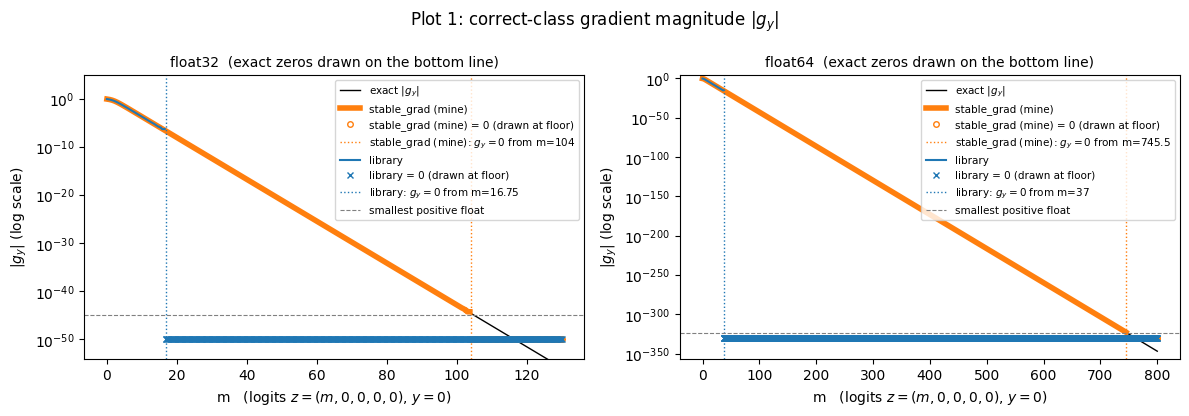

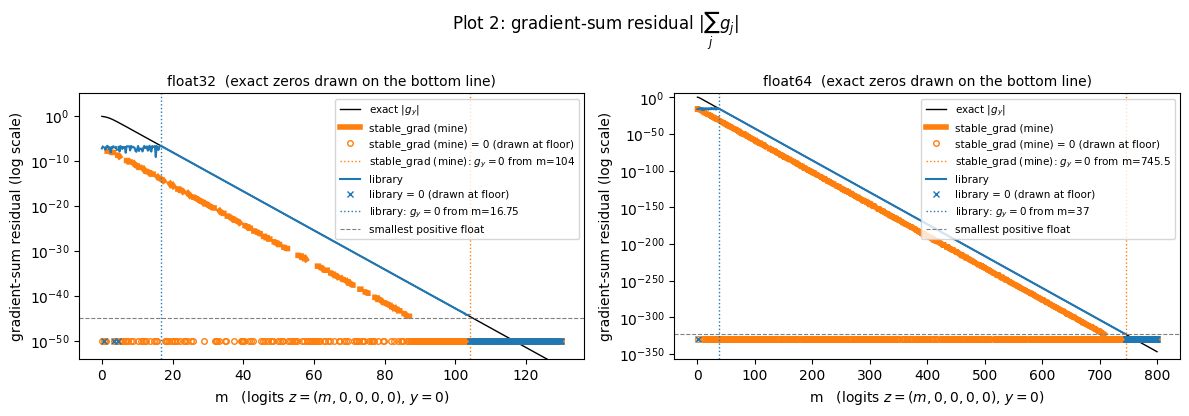

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------- data: scan z(m) = (m,0,0,0,0), y = 0, for both methods ----------
def scan_methods(dtype, ms):
    out = {k: np.zeros(len(ms)) for k in ("lib_gy", "mine_gy", "lib_sum", "mine_sum")}
    for i, m in enumerate(ms):
        z = torch.tensor([m, 0., 0., 0., 0.], dtype=dtype)
        gl, gm = library_gradient(float(m), dtype), stable_grad(z, 0)
        out["lib_gy"][i],  out["mine_gy"][i]  = abs(gl[0].item()), abs(gm[0].item())
        out["lib_sum"][i], out["mine_sum"][i] = abs(gl.sum().item()), abs(gm.sum().item())
    return out

grids = {torch.float32: np.arange(0., 130.25, 0.25), torch.float64: np.arange(0., 800.5, 0.5)}
scans = {dt: scan_methods(dt, ms) for dt, ms in grids.items()}

# exact |g_y| = 4e^-m / (1 + 4e^-m), evaluated in log10 so it can go below the smallest float
def log10_exact_gy(m):
    return (np.log10(4.) - m * np.log10(np.e)) - np.log1p(4. * np.exp(-m)) / np.log(10.)

# ---------- plotting ----------
FLOOR = {torch.float32: -50., torch.float64: -330.}      # exact zeros are drawn at this log10 height
NAMES = {"mine": ("stable_grad (mine)", "C1", "o", 4), "lib": ("library", "C0", "x", 1.5)}   # label, colour, marker, linewidth

def plot_metric(key, title, ylabel):
    """key = 'gy' for |g_y|, 'sum' for |sum_j g_j|."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, (dt, ms) in zip(axes, grids.items()):
        floor = FLOOR[dt]
        smallest = np.log10(float(torch.tensor(0., dtype=dt).nextafter(torch.tensor(1., dtype=dt))))
        ax.plot(ms, log10_exact_gy(ms), "k-", lw=1, label="exact $|g_y|$")
        for who, (name, color, marker, lw) in NAMES.items():
            v = scans[dt][f"{who}_{key}"]
            zero = v == 0
            ax.plot(ms, np.where(zero, np.nan, np.log10(np.where(zero, 1., v))), color=color, lw=lw, label=name)   # line stops at zeros
            ax.plot(ms[zero], np.full(zero.sum(), floor), marker, ms=4, color=color,
                    mfc="none" if marker == "o" else color, ls="none", label=f"{name} = 0 (drawn at floor)")
            g = scans[dt][f"{who}_gy"]                   # first m where |g_y| is exactly 0, shown in the legend
            if (g == 0).any():
                m0 = ms[np.argmax(g == 0)]
                ax.axvline(m0, color=color, ls=":", lw=1, label=f"{name}: $g_y=0$ from m={m0:g}")
        ax.axhline(smallest, color="gray", ls="--", lw=0.8, label="smallest positive float")
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"$10^{{{round(v)}}}$"))
        ax.set_ylim(floor - 0.08 * abs(floor), 5)
        ax.set_title(f"{str(dt).replace('torch.', '')}  (exact zeros drawn on the bottom line)", fontsize=10)
        ax.set_xlabel("m   (logits $z=(m,0,0,0,0)$, $y=0$)"); ax.set_ylabel(ylabel)
        ax.legend(loc="upper right", fontsize=7.5)
    fig.suptitle(title); fig.tight_layout(); plt.show()

from decimal import Decimal, getcontext
getcontext().prec = 80

def plot_relative_error():
    """Plot 3 (extra): relative error of the computed |g_y| against m, vs an 80-digit Decimal reference."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, (dt, ms) in zip(axes, grids.items()):
        exact = [4 / (Decimal(float(m)).exp() + 4) for m in ms]          # exact |g_y| = 4/(e^m+4), high precision
        ok = np.array([float(e) >= torch.finfo(dt).tiny for e in exact])  # judge only values that are normal floats of this dtype
        for who, (name, color, marker, lw) in NAMES.items():
            v = scans[dt][f"{who}_gy"]
            err = np.array([float(abs(Decimal(float(v[i])) - exact[i]) / exact[i]) if ok[i] else np.nan for i in range(len(ms))])
            ax.plot(ms, np.maximum(err, 1e-20), color=color, lw=lw, label=name)           # an error of exactly 0 would be drawn at 1e-20
        ax.axhline(torch.finfo(dt).eps, color="gray", ls="--", lw=0.8, label="machine epsilon")
        ax.axhline(1.0, color="k", ls=":", lw=0.8, label="relative error 1 (100% wrong)")
        ax.set_yscale("log"); ax.set_ylim(1e-20, 10)
        ax.set_title(f"{str(dt).replace('torch.', '')}  (only where the true $|g_y|$ is a normal float)", fontsize=10)
        ax.set_xlabel("m   (logits $z=(m,0,0,0,0)$, $y=0$)"); ax.set_ylabel(r"relative error of $|g_y|$")
        ax.legend(loc="center right", bbox_to_anchor=(1, 0.8), fontsize=7.5)
    fig.suptitle("Plot 3: relative error of the correct-class gradient"); fig.tight_layout(); plt.show()

plot_metric("gy",  "Plot 1: correct-class gradient magnitude $|g_y|$", "$|g_y|$ (log scale)")
plot_metric("sum", r"Plot 2: gradient-sum residual $|\sum_j g_j|$",   "gradient-sum residual (log scale)")

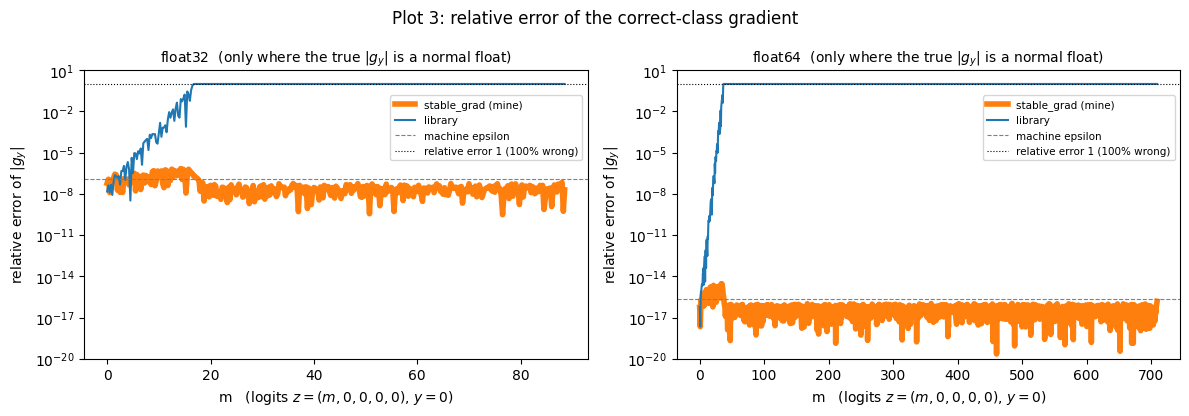

In [17]:
plot_relative_error()

*Comment on the two plots.*

**What the two plots show:**

*Plot 1 ($|g_y|$).* Both methods follow the exact curve $4/(e^m+4)$ at first. The library then returns exactly $0$ at $m=16.75$ (float32) and $m\approx37$ (float64), although the true value there ($\approx2\times10^{-7}$ and $\approx10^{-16}$) is easily representable. This is the cancellation in $p_y-1$. `stable_grad` stays on the exact curve until the true value itself drops below the smallest positive float, at $m=104$ (float32) and $m\approx745$ (float64). It then also returns $0$, which is the best any method can do in that format.

*Plot 2 ($|\sum_j g_j|$).* The gradients must sum to zero. The gray line is the true size of $g_y$, so the distance of a curve from it tells how much of $g_y$ is missing. Before its collapse the library's residual is a flat rounding-noise floor ($\sim10^{-7}$ in float32, $\sim10^{-16}$ in float64). After the collapse it runs along the gray line, because the residual is now exactly the size of the lost $g_y$ (e.g. at $m=20$ in float32: $g_0=0$ and $\sum_j g_j=8.2\times10^{-9}=4g_1$). Note that a small residual is not good by itself: at $m=40$ it is $1.7\times10^{-17}$, but that is the whole of $g_y$. `stable_grad`'s residual stays far below the gray line, about one rounding error of $|g_y|$. It flickers between exactly $0$ (a gap, since zero has no logarithm) and that one rounding error, depending on how the rounding falls.



*Plot 3 (relative error).* Against an 80-digit reference, the library's relative error rises from about $10^{-7}$ to $75\%$ at $m=16.5$ in float32 and is exactly $100\%$ (it returns $0$) from $m=16.75$; the float64 library behaves the same way from $m\approx37$. `stable_grad` stays at about $10^{-7}$ (float32) and $10^{-16}$ (float64), i.e. machine epsilon, until the true value stops being a normal float. So the cancellation in $p_y-1$ is already visible before $g_y$ becomes zero.

**Required additional tests.**

**(a) A non-zero target index.**

**(b) A different $K$.**

**(c) Extremely large logit differences.**

In [18]:
def rel_err_or_na(g, ref, dtype):
    if all(abs(r) < torch.finfo(dtype).tiny for r in ref):
        return "n/a (true gradient is 0 or below the smallest float)"
    return f"{max_rel_err(g, ref, dtype):.1e}"

def report(cases, dtype, caption):
    rows = []
    for name, z, y in cases:
        z = z.to(dtype)
        ref, gm, gl = exact_grad(z, y), stable_grad(z, y), lib_grad(z, y)
        rows.append({"case": name,
                     "exact g_y": f"{float(ref[y]):.3e}",
                     "library g_y": f"{gl[y].item():.3e}",
                     "mine g_y": f"{gm[y].item():.3e}",
                     "rel err library": rel_err_or_na(gl, ref, dtype),
                     "rel err mine": rel_err_or_na(gm, ref, dtype),
                     "|sum| library": f"{gl.sum().abs().item():.1e}",
                     "|sum| mine": f"{gm.sum().abs().item():.1e}"})
    display(pd.DataFrame(rows).style.set_caption(caption).hide(axis="index"))

def with_target(K, y, m, seed=SEED):          # random N(0,1) logits, then raise the target logit by m
    g = torch.Generator().manual_seed(seed)
    z = torch.randn(K, generator=g); z[y] += m
    return z

cases_a = [   # (a) non-zero target index
    ("K=5, y=3, z=(0,0,0,30,0)",               torch.tensor([0., 0, 0, 30., 0]), 3),
    ("K=5, y=4, z=(0,0,0,0,60)",               torch.tensor([0., 0, 0, 0, 60.]), 4),
    ("K=5, y=1, target is NOT the max",        torch.tensor([0., 0, 0, 30., 0]), 1),
]
cases_b = [   # (b) different K
    ("K=2, y=1, z=(0,40)",                     torch.tensor([0., 40.]), 1),
    ("K=10, y=6, target +40",                  with_target(10, 6, 40.), 6),
    ("K=1000, y=999, target +40",              with_target(1000, 999, 40.), 999),
]
cases_c = [   # (c) extremely large logit differences
    ("z=(1e4,-1e4,0), y=0 (very confident)",     torch.tensor([1e4, -1e4, 0.]), 0),
    ("z=(1e4,-1e4,0), y=1 (confidently wrong)",  torch.tensor([1e4, -1e4, 0.]), 1),
    ("z=(1e4,-1e4,0), y=2 (confidently wrong)",  torch.tensor([1e4, -1e4, 0.]), 2),
]
for tag, cases in (("(a) non-zero target", cases_a), ("(b) different K", cases_b), ("(c) extreme logit differences", cases_c)):
    for dtype in (torch.float32, torch.float64):
        report(cases, dtype, f"{tag}, {dtype}")

case,exact g_y,library g_y,mine g_y,rel err library,rel err mine,|sum| library,|sum| mine
"K=5, y=3, z=(0,0,0,30,0)",-3.743e-13,0.000e+00,-3.743e-13,1.0e+00,6.1e-09,3.7e-13,0.0e+00
"K=5, y=4, z=(0,0,0,0,60)",-3.503e-26,0.000e+00,-3.503e-26,1.0e+00,1.5e-08,3.5e-26,1.5e-33
"K=5, y=1, target is NOT the max",-1.000e+00,-1.000e+00,-1.000e+00,6.1e-09,6.1e-09,0.0e+00,0.0e+00


case,exact g_y,library g_y,mine g_y,rel err library,rel err mine,|sum| library,|sum| mine
"K=5, y=3, z=(0,0,0,30,0)",-3.743e-13,-3.744e-13,-3.743e-13,1.7e-04,1.2e-15,6.2e-17,0.0e+00
"K=5, y=4, z=(0,0,0,0,60)",-3.503e-26,0.000e+00,-3.503e-26,1.0e+00,3.4e-17,3.5e-26,2.9e-42
"K=5, y=1, target is NOT the max",-1.000e+00,-1.000e+00,-1.000e+00,1.2e-15,1.3e-15,0.0e+00,0.0e+00


case,exact g_y,library g_y,mine g_y,rel err library,rel err mine,|sum| library,|sum| mine
"K=2, y=1, z=(0,40)",-4.248e-18,0.000e+00,-4.248e-18,1.0e+00,2.9e-08,4.2e-18,0.0e+00
"K=10, y=6, target +40",-3.220e-17,0.000e+00,-3.220e-17,1.0e+00,1.7e-06,3.2e-17,1.7e-24
"K=1000, y=999, target +40",-1.415e-14,0.000e+00,-1.415e-14,1.0e+00,1.9e-06,1.4e-14,8.5e-22


case,exact g_y,library g_y,mine g_y,rel err library,rel err mine,|sum| library,|sum| mine
"K=2, y=1, z=(0,40)",-4.248e-18,0.000e+00,-4.248e-18,1.0e+00,2.5e-17,4.2e-18,0.0e+00
"K=10, y=6, target +40",-3.220e-17,0.000e+00,-3.220e-17,1.0e+00,8.5e-17,3.2e-17,1.5e-33
"K=1000, y=999, target +40",-1.415e-14,-1.421e-14,-1.415e-14,4.6e-03,1.6e-16,6.5e-17,0.0e+00


case,exact g_y,library g_y,mine g_y,rel err library,rel err mine,|sum| library,|sum| mine
"z=(1e4,-1e4,0), y=0 (very confident)",-0.000e+00,0.000e+00,-0.000e+00,n/a (true gradient is 0 or below the smallest float),n/a (true gradient is 0 or below the smallest float),0.0e+00,0.0e+00
"z=(1e4,-1e4,0), y=1 (confidently wrong)",-1.000e+00,-1.000e+00,-1.000e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
"z=(1e4,-1e4,0), y=2 (confidently wrong)",-1.000e+00,-1.000e+00,-1.000e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00


case,exact g_y,library g_y,mine g_y,rel err library,rel err mine,|sum| library,|sum| mine
"z=(1e4,-1e4,0), y=0 (very confident)",-0.000e+00,0.000e+00,-0.000e+00,n/a (true gradient is 0 or below the smallest float),n/a (true gradient is 0 or below the smallest float),0.0e+00,0.0e+00
"z=(1e4,-1e4,0), y=1 (confidently wrong)",-1.000e+00,-1.000e+00,-1.000e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
"z=(1e4,-1e4,0), y=2 (confidently wrong)",-1.000e+00,-1.000e+00,-1.000e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00


**(a) Non-zero target.** For target logit $30$ the library gives $g_y=0$ in float32 and an inexact value in float64 (relative error $1.7\times10^{-4}$), and for target logit $60$ it gives $0$ in both dtypes. `stable_grad` is within $1.5\times10^{-8}$ (float32) and $1.2\times10^{-15}$ (float64) of the exact value. When the target is *not* the largest logit, $p_y$ is not near $1$, and both methods agree.

**(b) Different $K$.** For $K=2$, $K=10$ and $K=1000$ with a confident correct prediction (target logit raised by $40$), the library returns $g_y=0$ in float32 for all three, and in float64 for $K=2$ and $K=10$ (for $K=1000$ it is $0.46\%$ off). `stable_grad` stays within $2\times10^{-6}$ (float32) and $2\times10^{-16}$ (float64) of the exact value; its error is about the same for $K=10$ and $K=1000$ in float32 ($1.7\times10^{-6}$ vs $1.9\times10^{-6}$) and only slightly larger for $K=1000$ in float64, so it is set mainly by the logit scale (here $z_y+40$), not by $K$.

**(c) Extreme logit differences** (spread $2\times10^{4}$). If the model is confidently *wrong* ($y=1$ or $2$), $p_y\approx0$ and $g_y=p_y-1=-1$: no cancellation occurs, and both methods return exactly $-1$. If it is confidently *right* ($y=0$), the true gradients are about $e^{-10^4}\approx10^{-4343}$, far below the smallest float in any dtype. Both methods return $0$, and that is the correct representable answer, so no method can do better.



**Limitations — stability is not infinite precision.**
- A fixed format cannot store arbitrarily small non-zero numbers. `stable_grad` returns the correct $g_y$ only while the true value is representable: it is exact (to rounding) up to $m\approx104$ in float32 and $m\approx745$ in float64, and returns $0$ beyond that, because $4e^{-m}$ is then below half the smallest positive float ($2^{-150}$ and $2^{-1075}$). Between about $m=87$ and $104$ in float32 the values are denormal and carry only a few significant digits (e.g. $-1.513\times10^{-43}$ against the true $-1.488\times10^{-43}$ at $m=100$).
- For an extreme spread like $(10^4,-10^4,0)$ the true gradients are $\approx10^{-4343}$, so every method returns $0$, which is right but uninformative.
- The remaining error of `stable_grad` is rounding of the order of the machine epsilon times the size of the logits, since $z_j-\mathrm{lse}(\mathbf z)$ is computed in floating point. It grows with the logit scale and depends only mildly on $K$ (about $2\times10^{-6}$ in float32 for both $K=10$ and $K=1000$ with a $+40$ target).
- It repairs the *gradient* of the loss at high confidence. It does not make a gradient meaningful where the true value cannot be stored.

In [19]:
ms_fine = np.arange(0., 800.25, 0.25)
rows = []
for dt in (torch.float32, torch.float64):
    lib0, lib1, mine0 = (np.zeros(len(ms_fine)) for _ in range(3))
    for i, m in enumerate(ms_fine):
        gl = library_gradient(float(m), dt); lib0[i], lib1[i] = gl[0].item(), gl[1].item()
        mine0[i] = stable_grad(torch.tensor([m, 0., 0., 0., 0.], dtype=dt), 0)[0].item()
    exact = 4 * np.exp(-ms_fine) / (1 + 4 * np.exp(-ms_fine))          # float64 reference for |g_y|
    ok = exact >= torch.finfo(dt).tiny                                   # judge only values that are normal floats
    first = lambda mask: f"{ms_fine[np.argmax(mask)]:g}" if mask.any() else "none"
    collapse = (lib0 == 0) & (lib1 != 0)
    before = ok & (ms_fine < ms_fine[np.argmax(collapse)])               # library range before its collapse
    rel = lambda g, sel: np.max(np.abs(np.abs(g[sel]) - exact[sel]) / exact[sel])
    rows.append({"dtype": str(dt).replace("torch.", ""),
                 "library g_y first exactly 0 at m": first(collapse),
                 "all library gradients 0 at m": first((lib0 == 0) & (lib1 == 0)),
                 "stable_grad g_y first 0 at m": first(mine0 == 0),
                 "library max rel. error before collapse": f"{rel(lib0, before):.1e}",
                 "stable_grad max rel. error (normal-float range)": f"{rel(mine0, ok):.1e}"})
display(pd.DataFrame(rows).set_index("dtype").T.style.set_caption("Summary, z = (m,0,0,0,0), y = 0"))

dtype,float32,float64
library g_y first exactly 0 at m,16.75,36.75
all library gradients 0 at m,104,745.25
stable_grad g_y first 0 at m,104,745.25
library max rel. error before collapse,7.5e-01,5.8e-01
stable_grad max rel. error (normal-float range),7.0e-07,3.8e-15


## Reflection

**1. Why did the naïve calculation in Part I fail, and what changed after the reformulation?**
$e^{1000}$ is far above the largest float in both dtypes so $e^a$ and $e^b$ both became `inf` and $\log(\infty+\infty)=\infty$, although the true value is about $1000.31$. For very negative inputs the same formula underflows to $0$ and gives $-\infty$. After factoring out $e^{c}$ with $c=\max(a,b)$, only $e^{a-c}$ and $e^{b-c}$ are computed: they lie in $(0,1]$, the sum lies in $[1,n]$, and the result is finite and matches `torch.logaddexp`/`logsumexp`.

**2. Overflow versus cancellation.**
Overflow is a *range* problem: a number is too large to store, the result is `inf`/`nan`, it is visible, and rescaling by the maximum fixes it. Cancellation is a *precision* problem: subtracting two almost equal numbers (here $p_y-1$ with $p_y\approx1$) destroys the leading digits, so the answer is finite and plausible but wrong. In Part III the library's $g_y$ became exactly $0$ at $m\approx17$ (float32) and $m\approx37$ (float64), although the true values ($\approx10^{-7}$, $10^{-16}$) were representable.

**3. Does a reasonable loss guarantee a reliable gradient?**
No. At $m=20$ in float32 the loss is $\approx8\times10^{-9}$, which looks perfectly sensible, yet the library's $g_y$ was exactly $0$ while the true value is $-8.2\times10^{-9}$, and the gradients no longer summed to zero.

**4. What does my solution improve, and what does it not guarantee?**
It keeps $g_y$ correct (relative error about $10^{-6}$ in float32 and $10^{-15}$ in float64 in the tables above) for as long as the true value is representable, i.e. up to $m\approx104$ and $m\approx745$. It does not create precision that the format lacks: beyond those points, and for extreme spreads like $(10^4,-10^4,0)$, every method returns $0$; values in the denormal range have only a few correct digits; and the remaining error grows with the logit scale. It also fixes only this gradient, not every operation in a network.

*Revisiting the open question from Part II:* I originally guessed that a stable log-sum-exp makes everything related stable. That was wrong: it protects the loss, but the gradient's $p_y-1$ still cancels.

## Use of AI tools

Claude (Anthropic) was used to assist in the following tasks

- *Setup:* creating the empty notebook layout from the problem sheet.

* **Code:**  writing the code, which we further improved and corrected ourselves, as it often had mistakes. It was also used in writing the analysis and plotting code.

- *Writing up derivations:* the derivations and predictions were worked out by us, by hand; Claude converted them to LaTeX/markdown and corrected one inequality condition in our Part I argument.
- Explanations: concepts such as float overflow/underflow thresholds, denormal numbers, cancellation.
- *Text:* drafts of the observation paragraphs, limitations and reflection.